## 矩阵乘法

学习以下内容：

块级矩阵乘法。
多维指针算术。
为提高 L2 缓存命中率而进行的程序重排序。
自动性能调优。

## 动机
矩阵乘法是现代大多数高性能计算系统的关键构建块。

矩阵乘法难以优化，因此其实现通常由硬件供应商自行完成，作为所谓「内核库」（例如 cuBLAS ）的一部分。

这些库通常是专有的，不能轻易定制以满足现代深度学习工作负载的需求（例如融合激活函数）。

在本教程中，您将学习如何借助一种更易于定制和扩展的方法，用 Triton 实现高效的矩阵乘法。

整体来说，我们将编写的内核将实现以下的分块算法，用于计算一个 (M, K) 乘以一个 (K, N) 的矩阵：

- Tiled Matrix Multiplication（分块矩阵乘法）
```python
# Do in parallel
# 并行进行
for m in range(0, M, BLOCK_SIZE_M):
  # Do in parallel
  # 并行进行
  for n in range(0, N, BLOCK_SIZE_N):
    acc = zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=float32)
    for k in range(0, K, BLOCK_SIZE_K):
      a = A[m : m+BLOCK_SIZE_M, k : k+BLOCK_SIZE_K]
      b = B[k : k+BLOCK_SIZE_K, n : n+BLOCK_SIZE_N]
      acc += dot(a, b)
    C[m : m+BLOCK_SIZE_M, n : n+BLOCK_SIZE_N] = acc

```

## 计算内核
实际上，上述算法在 Triton 中实现起来相当简单。

主要困难在于计算内循环中必须读取 A 和 B 块的内存位置。为此，我们需要多维指针算术。

## 指针算术

因此，对于行主序的二维张量 X，X[i, j] 的内存位置由 &X[i, j] = X + i*stride_xi + j*stride_xj 给出。

因此，A[m : m+BLOCK_SIZE_M, k:k+BLOCK_SIZE_K]和B[k : k+BLOCK_SIZE_K, n:n+BLOCK_SIZE_N] 的指针块可以用伪代码定义为：
```python
&A[m : m+BLOCK_SIZE_M, k:k+BLOCK_SIZE_K] = a_ptr + (m : m+BLOCK_SIZE_M)[:, None]*A.stride(0) + (k : k+BLOCK_SIZE_K)[None, :]*A.stride(1);
&B[k : k+BLOCK_SIZE_K, n:n+BLOCK_SIZE_N] = b_ptr + (k : k+BLOCK_SIZE_K)[:, None]*B.stride(0) + (n : n+BLOCK_SIZE_N)[None, :]*B.stride(1);
```

## L2 缓存优化

正如上面提到的，每个程序实例计算 C 的一个 [BLOCK_SIZE_M, BLOCK_SIZE_N] 块。

重点要记住这些块的计算顺序，因为它会影响我们程序的 L2 缓存命中率，而且，简单的行主序排序是行不通的。

```python
pid = tl.program_id(axis=0)
grid_n = tl.cdiv(N, BLOCK_SIZE_N)
pid_m = pid // grid_n
pid_n = pid % grid_n

```

在转向下一列之前，可以通过将 GROUP_M 行的块进行「超级分组」来实现此目的：
```python

# 程序 ID
pid = tl.program_id(axis=0)
# Number of program ids along the M axis
# M 轴上程序 id 的数量
num_pid_m = tl.cdiv(M, BLOCK_SIZE_M)

# N 轴上程序 id 的数量
num_pid_n = tl.cdiv(N, BLOCK_SIZE_N)

# 总程序数量=num_pid_m*num_pid_n，下面是计算一组中程序的数量
num_pid_in_group = GROUP_SIZE_M * num_pid_n

# 本程序所在的组 id（属于哪一个组）
group_id = pid // num_pid_in_group

# 组内第一个程序的行 id
first_pid_m = group_id * GROUP_SIZE_M

# 如果 `num_pid_m` 不能被 `GROUP_SIZE_M` 整除，最后一组会比较小
group_size_m = min(num_pid_m - first_pid_m, GROUP_SIZE_M)

# 在组内，程序按列主序排序。

# 启动网格中程序的行 id
pid_m = first_pid_m + ((pid % num_pid_in_group) % group_size_m)

# 启动网格中程序的列 id
pid_n = (pid % num_pid_in_group) // group_size_m

```


>Grouped Ordering 的核心思想之一，就是在 A Tile 和 B Tile 的缓存复用之间取得平衡，尽量提高 L2 Cache 的命中率

实际硬件调度仍然有自己的工作分配机制。某些设备和执行情况下，编号相近的 Block 可能在相近的时间窗口内被调度

假设：
```python
num_pid_m = 5
num_pid_n = 3
GROUP_SIZE_M = 2
```

则：
Group 0:  
pid 0 → (0,0)  
pid 1 → (1,0)  
pid 2 → (0,1)  
pid 3 → (1,1)   
pid 4 → (0,2)  
pid 5 → (1,2)  

Group 1:  
pid 6  → (2,0)  
pid 7  → (3,0)  
pid 8  → (2,1)  
pid 9  → (3,1)  
pid 10 → (2,2)  
pid 11 → (3,2)  

Group 2:  
pid 12 → (4,0)  
pid 13 → (4,1)  
pid 14 → (4,2)  


## 代码

In [2]:
import torch


import triton
import triton.language as tl




def is_cuda():
    return triton.runtime.driver.active.get_current_target().backend == "cuda"




def is_hip_mi200():
    target = triton.runtime.driver.active.get_current_target()
    return target.backend == 'hip' and target.arch == 'gfx90a'




def get_cuda_autotune_config():
    return [
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=3,
                      num_warps=8),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 32, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 32, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=5,
                      num_warps=2),
        triton.Config({'BLOCK_SIZE_M': 32, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=5,
                      num_warps=2),
        # Good config for fp8 inputs.
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=3,
                      num_warps=8),
        triton.Config({'BLOCK_SIZE_M': 256, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=3,
                      num_warps=8),
        triton.Config({'BLOCK_SIZE_M': 256, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 32, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=4,
                      num_warps=4)
    ]




def get_hip_autotune_config():
    return [
        triton.Config(
            {'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 16, 'GROUP_SIZE_M': 1, 'waves_per_eu': 2},
            num_warps=4, num_stages=0),
        triton.Config(
            {'BLOCK_SIZE_M': 256, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 16, 'GROUP_SIZE_M': 4, 'waves_per_eu': 2},
            num_warps=8, num_stages=0),
        triton.Config(
            {'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 1, 'waves_per_eu': 2},
            num_warps=8, num_stages=0),
        triton.Config(
            {'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8, 'waves_per_eu': 3},
            num_warps=4, num_stages=0),
        triton.Config(
            {'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 1, 'waves_per_eu': 8},
            num_warps=4, num_stages=0),
    ]




def get_autotune_config():
    if is_cuda():
        return get_cuda_autotune_config()
    else:
        return get_hip_autotune_config()




# `triton.jit`'ed functions can be auto-tuned by using the `triton.autotune` decorator, which consumes:
# `triton.jit` 函数可以通过使用 `triton.autotune` 装饰器进行自动调优，该装饰器接受以下内容：
#   - A list of `triton.Config` objects that define different configurations of
#       meta-parameters (e.g., `BLOCK_SIZE_M`) and compilation options (e.g., `num_warps`) to try
#   - 一组 `triton.Config` 对象的列表，这些对象定义了不同的元参数配置（例如 `BLOCK_SIZE_M`）和编译选项（例如 `num_warps`）以供尝试。
#   - An auto-tuning *key* whose change in values will trigger evaluation of all the
#       provided configs
# - 一个自动调优的 key，其值的变化将触发对所有提供的配置进行评估。


@triton.autotune(
    configs=get_autotune_config(),
    key=['M', 'N', 'K'],
)
@triton.jit
def matmul_kernel(
        # Pointers to matrices
        # 矩阵指针
        a_ptr, b_ptr, c_ptr,
        # Matrix dimensions
        # 矩阵维度
        M, N, K,
        # The stride variables represent how much to increase the ptr by when moving by 1
        # element in a particular dimension. E.g. `stride_am` is how much to increase `a_ptr`
        # by to get the element one row down (A has M rows).
        # 这些步幅变量表示在特定维度移动 1 个元素时，`ptr` 应该增加多少。例如，`stride_am` 指示了为了访问下一行的元素（假设 `A` 有 `M` 行），需要增加多少 `a_ptr`。
        stride_am, stride_ak,  #
        stride_bk, stride_bn,  #
        stride_cm, stride_cn,
        # Meta-parameters
        # 元参数
        BLOCK_SIZE_M: tl.constexpr, BLOCK_SIZE_N: tl.constexpr, BLOCK_SIZE_K: tl.constexpr,  #
        GROUP_SIZE_M: tl.constexpr,  #
        ACTIVATION: tl.constexpr  #
):
    """Kernel for computing the matmul C = A x B.
    A has shape (M, K), B has shape (K, N) and C has shape (M, N)
    """
    """计算矩阵乘法 C = A x B 的核心算法。
    其中，A 的形状为 (M, K)，B 的形状为 (K, N)，C 的形状为 (M, N)。
    """
    # -----------------------------------------------------------
    # Map program ids `pid` to the block of C it should compute.
    # 将程序 ID `pid` 映射到它应计算的 C 块。
    # This is done in a grouped ordering to promote L2 data reuse.
    # 这是按组顺序进行的，以促进 L2 数据重用。
    # See above `L2 Cache Optimizations` section for details.
    # 详细信息请参见上述的 `L2 缓存优化` 部分。

    pid = tl.program_id(axis=0)
    num_pid_m = tl.cdiv(M, BLOCK_SIZE_M)
    num_pid_n = tl.cdiv(N, BLOCK_SIZE_N)
    num_pid_in_group = GROUP_SIZE_M * num_pid_n
    group_id = pid // num_pid_in_group
    first_pid_m = group_id * GROUP_SIZE_M
    group_size_m = min(num_pid_m - first_pid_m, GROUP_SIZE_M)
    pid_m = first_pid_m + ((pid % num_pid_in_group) % group_size_m)
    pid_n = (pid % num_pid_in_group) // group_size_m


    # ----------------------------------------------------------
    # Create pointers for the first blocks of A and B.
    # 创建 A 和 B 第一个块的指针
    # We will advance this pointer as we move in the K direction
    # and accumulate
    # 在沿着 K 方向移动时，我们将推进这个指针并累加
    # `a_ptrs` is a block of [BLOCK_SIZE_M, BLOCK_SIZE_K] pointers
    # `a_ptrs` 是一个 [BLOCK_SIZE_M, BLOCK_SIZE_K] 大小的指针块
    # `b_ptrs` is a block of [BLOCK_SIZE_K, BLOCK_SIZE_N] pointers
    # `b_ptrs` 是一个 [BLOCK_SIZE_K, BLOCK_SIZE_N] 大小的指针块


    # See above `Pointer Arithmetic` section for details
    # 详细信息请参见上述的 `指针算术` 部分。
    offs_am = (pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)) % M
    offs_bn = (pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)) % N
    offs_k = tl.arange(0, BLOCK_SIZE_K)
    a_ptrs = a_ptr + (offs_am[:, None] * stride_am + offs_k[None, :] * stride_ak)
    b_ptrs = b_ptr + (offs_k[:, None] * stride_bk + offs_bn[None, :] * stride_bn)


    # -----------------------------------------------------------
    # Iterate to compute a block of the C matrix.
    # 迭代计算 C 矩阵的一个块。
    # We accumulate into a `[BLOCK_SIZE_M, BLOCK_SIZE_N]` block
    # of fp32 values for higher accuracy.
    # 我们累加到一个 `[BLOCK_SIZE_M, BLOCK_SIZE_N]` 大小的 fp32 值块，以提高精度。
    # `accumulator` will be converted back to fp16 after the loop.
    # `accumulator` 在循环结束后将转换回 fp16。
    accumulator = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=tl.float32)
    for k in range(0, tl.cdiv(K, BLOCK_SIZE_K)):
        # Load the next block of A and B, generate a mask by checking the K dimension.
        # 加载 A 和 B 的下一个块，通过检查 K 维度生成一个掩码。
        # If it is out of bounds, set it to 0.
        # 如果超出边界设为 0
        a = tl.load(a_ptrs, mask=offs_k[None, :] < K - k * BLOCK_SIZE_K, other=0.0)
        b = tl.load(b_ptrs, mask=offs_k[:, None] < K - k * BLOCK_SIZE_K, other=0.0)
        # We accumulate along the K dimension.
        # 通过着 K 维度进行累加。
        accumulator = tl.dot(a, b, accumulator)
        # Advance the ptrs to the next K block.
        # 指针前进到下一个 K 块。
        a_ptrs += BLOCK_SIZE_K * stride_ak
        b_ptrs += BLOCK_SIZE_K * stride_bk
    # You can fuse arbitrary activation functions here
    # while the accumulator is still in FP32!
    # 在累加器仍然是 FP32 的情况下，您可以在这里融合任意激活函数！
    if ACTIVATION == "leaky_relu":
        accumulator = leaky_relu(accumulator)
    c = accumulator.to(tl.float16)


    # -----------------------------------------------------------
    # Write back the block of the output matrix C with masks.
    # 写回带有掩码的输出矩阵 C 的块。
    offs_cm = pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
    offs_cn = pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
    c_ptrs = c_ptr + stride_cm * offs_cm[:, None] + stride_cn * offs_cn[None, :]
    c_mask = (offs_cm[:, None] < M) & (offs_cn[None, :] < N)
    tl.store(c_ptrs, c, mask=c_mask)




# We can fuse `leaky_relu` by providing it as an `ACTIVATION` meta-parameter in `matmul_kernel`.
# 我们可以通过在 `matmul_kernel` 中将 `leaky_relu` 作为 `ACTIVATION` 元参数来融合 `leaky_relu`。
@triton.jit
def leaky_relu(x):
    return tl.where(x >= 0, x, 0.01 * x)



## 测试

对自定义矩阵乘法操作进行测试，与 原生 torch 实现（例如 cuBLAS）进行对比。

In [6]:
def matmul(a, b, activation=""):
    M, K = a.shape
    K_b, N = b.shape
    assert K == K_b, "A 的列数必须等于 B 的行数"
    assert a.device == b.device, "A 和 B 必须在同一设备上"

    # 当前 kernel 会将结果转换成 FP16。
    c = torch.empty((M, N), device=a.device, dtype=torch.float16)

    # 每个 program 计算一个输出块。
    # 自动调优时，使用当前候选配置中的块大小计算 program 数量。
    grid = lambda meta: (
        triton.cdiv(M, meta["BLOCK_SIZE_M"])
        * triton.cdiv(N, meta["BLOCK_SIZE_N"]),
    )

    matmul_kernel[grid](
        a, b, c,
        M, N, K,
        a.stride(0), a.stride(1),
        b.stride(0), b.stride(1),
        c.stride(0), c.stride(1),
        ACTIVATION=activation,
    )

    return c

torch.manual_seed(0)
a = torch.randn((512, 512), device='cuda', dtype=torch.float16)
b = torch.randn((512, 512), device='cuda', dtype=torch.float16)
triton_output = matmul(a, b)
torch_output = torch.matmul(a, b)
print(f"triton_output_with_fp16_inputs={triton_output}")
print(f"torch_output_with_fp16_inputs={torch_output}")
# Bigger tolerance for AMD MI200 devices.
# 对于 AMD MI200 设备，使用更大的容差。
# MI200 devices use reduced precision fp16 and bf16 and flush input and
# output denormal values to zero. Detailed info is at: https://pytorch.org/docs/stable/notes/numerical_accuracy.html#reduced-precision-fp16-and-bf16-gemms-and-convolutions-on-amd-instinct-mi200-devices
# MI200 设备使用降低精度的 FP16 和 BF16，并将输入和输出的非规格化值清零。详细信息在以下链接：https://pytorch.org/docs/stable/notes/numerical_accuracy.html#reduced-precision-fp16-and-bf16-gemms-and-convolutions-on-amd-instinct-mi200-devices
rtol = 1e-2 if is_hip_mi200() else 0
if torch.allclose(triton_output, torch_output, atol=1e-2, rtol=rtol):
    print("✅ Triton and Torch match")
else:
    print("❌ Triton and Torch differ")


TORCH_HAS_FP8 = hasattr(torch, "float8_e5m2")
if TORCH_HAS_FP8 and is_cuda():
    torch.manual_seed(0)
    a = torch.randn((512, 512), device="cuda", dtype=torch.float16)
    b = torch.randn((512, 512), device="cuda", dtype=torch.float16)
    a = a.to(torch.float8_e5m2)
    # pre-transpose b for efficiency.
    # 提前转置 b 提高效率
    b = b.T
    b = b.to(torch.float8_e5m2)
    triton_output = matmul(a, b)
    torch_output = torch.matmul(a.to(torch.float16), b.to(torch.float16))
    print(f"triton_output_with_fp8_inputs={triton_output}")
    print(f"torch_output_with_fp8_inputs={torch_output}")
    if torch.allclose(triton_output, torch_output, atol=0.125, rtol=0):
        print("✅ Triton and Torch match")
    else:
        print("❌ Triton and Torch differ")

triton_output_with_fp16_inputs=tensor([[-36.2188,   7.1211, -12.2891,  ...,  44.8125, -25.5156,   4.8477],
        [ 14.5078,   0.8687,   6.4805,  ...,  -2.8711, -15.1484, -18.2969],
        [-18.7344, -16.1562, -23.3125,  ...,   3.5605,  10.9062,   5.2305],
        ...,
        [ 50.4062, -30.9531, -16.8750,  ...,  12.7500,  23.3594,  13.8281],
        [-32.1250, -23.5156, -13.1406,  ..., -14.6406,  -5.3984,   8.5625],
        [ 16.0938, -22.2500, -21.6406,  ...,   1.9854,  16.3438,  22.2344]],
       device='cuda:0', dtype=torch.float16)
torch_output_with_fp16_inputs=tensor([[-36.2188,   7.1211, -12.2891,  ...,  44.8125, -25.5156,   4.8477],
        [ 14.5078,   0.8687,   6.4805,  ...,  -2.8711, -15.1484, -18.2969],
        [-18.7344, -16.1562, -23.3125,  ...,   3.5605,  10.9062,   5.2305],
        ...,
        [ 50.4062, -30.9531, -16.8750,  ...,  12.7500,  23.3594,  13.8281],
        [-32.1250, -23.5156, -13.1406,  ..., -14.6406,  -5.3984,   8.5625],
        [ 16.0938, -22.2500, -2

## 基准测试

比较内核与 cuBLAS 或 rocBLAS 的性能差异。此处以方阵为例进行讲解，也可以可以按需调整脚本，对其他 matrix shape 进行基准测试。

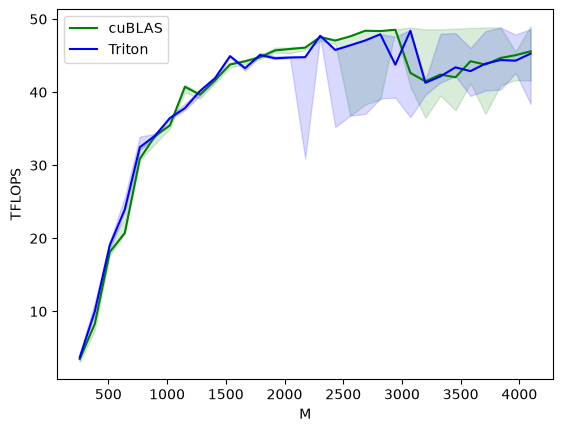

matmul-performance-fp16:
         M       N       K     cuBLAS     Triton
0    256.0   256.0   256.0   3.460647   3.692169
1    384.0   384.0   384.0   8.268561   9.968856
2    512.0   512.0   512.0  18.117944  19.065018
3    640.0   640.0   640.0  20.739240  23.953215
4    768.0   768.0   768.0  30.874103  32.467376
5    896.0   896.0   896.0  33.955965  34.007333
6   1024.0  1024.0  1024.0  35.451064  36.452397
7   1152.0  1152.0  1152.0  40.729536  37.812224
8   1280.0  1280.0  1280.0  39.658699  40.156863
9   1408.0  1408.0  1408.0  41.626541  41.916586
10  1536.0  1536.0  1536.0  43.783571  44.930057
11  1664.0  1664.0  1664.0  44.227490  43.283508
12  1792.0  1792.0  1792.0  44.778583  45.092974
13  1920.0  1920.0  1920.0  45.713341  44.634044
14  2048.0  2048.0  2048.0  45.911909  44.735513
15  2176.0  2176.0  2176.0  46.087437  44.784528
16  2304.0  2304.0  2304.0  47.543965  47.719078
17  2432.0  2432.0  2432.0  47.059403  45.779756
18  2560.0  2560.0  2560.0  47.638725  46.41

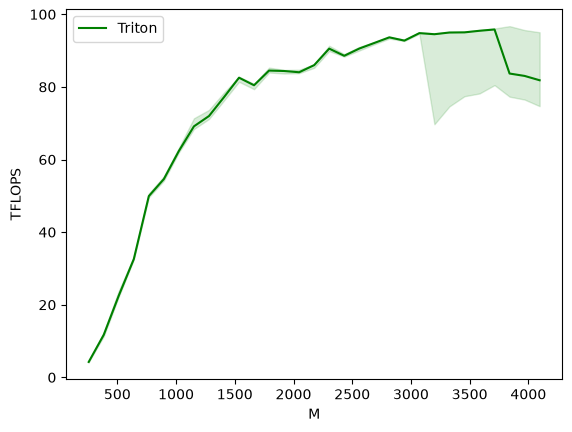

matmul-performance-fp8:
         M       N       K     Triton
0    256.0   256.0   256.0   4.245247
1    384.0   384.0   384.0  11.718358
2    512.0   512.0   512.0  22.519753
3    640.0   640.0   640.0  32.572565
4    768.0   768.0   768.0  49.932190
5    896.0   896.0   896.0  54.626606
6   1024.0  1024.0  1024.0  62.368830
7   1152.0  1152.0  1152.0  69.140003
8   1280.0  1280.0  1280.0  71.978034
9   1408.0  1408.0  1408.0  77.176215
10  1536.0  1536.0  1536.0  82.540970
11  1664.0  1664.0  1664.0  80.459677
12  1792.0  1792.0  1792.0  84.506951
13  1920.0  1920.0  1920.0  84.389167
14  2048.0  2048.0  2048.0  84.043659
15  2176.0  2176.0  2176.0  85.998493
16  2304.0  2304.0  2304.0  90.548679
17  2432.0  2432.0  2432.0  88.578044
18  2560.0  2560.0  2560.0  90.566245
19  2688.0  2688.0  2688.0  92.108950
20  2816.0  2816.0  2816.0  93.661811
21  2944.0  2944.0  2944.0  92.761346
22  3072.0  3072.0  3072.0  94.818774
23  3200.0  3200.0  3200.0  94.517260
24  3328.0  3328.0  3328.0

In [7]:
ref_lib = 'cuBLAS' if is_cuda() else 'rocBLAS'


configs = []
for fp8_inputs in [False, True]:
    if fp8_inputs and (not TORCH_HAS_FP8 or not is_cuda()):
        continue
    configs.append(
        triton.testing.Benchmark(
            x_names=["M", "N", "K"],  # Argument names to use as an x-axis for the plot 作为绘图 x 轴的参数名
            x_vals=[128 * i for i in range(2, 33)],  # Different possible values for `x_name` `x_names` 参数的不同可能值
            line_arg="provider",  # Argument name whose value corresponds to a different line in the plot 对应绘图中不同线的参数名
            # Possible values for `line_arg` `line_arg` 的可能值
            # Don't compare to cublas for fp8 cases as torch.matmul doesn't support fp8 at the moment. 在 fp8 情况下不与 cuBLAS 比较，因为 torch.matmul 目前不支持 fp8。
            line_vals=["triton"] if fp8_inputs else [ref_lib.lower(), "triton"],  # Label name for the lines
            line_names=["Triton"] if fp8_inputs else [ref_lib, "Triton"],  # Line styles
            styles=[("green", "-"), ("blue", "-")],
            ylabel="TFLOPS",  # Label name for the y-axis y 轴的标签名称
            plot_name="matmul-performance-" +
            ("fp16" if not fp8_inputs else "fp8"),  # Name for the plot, used also as a file 绘图名称，也用作保存绘图的文件名 name for saving the plot.
            args={"fp8_inputs": fp8_inputs},
        ))




@triton.testing.perf_report(configs)
def benchmark(M, N, K, provider, fp8_inputs):
    a = torch.randn((M, K), device='cuda', dtype=torch.float16)
    b = torch.randn((K, N), device='cuda', dtype=torch.float16)
    if TORCH_HAS_FP8 and fp8_inputs:
        a = a.to(torch.float8_e5m2)
        b = b.T
        b = b.to(torch.float8_e5m2)
    quantiles = [0.5, 0.2, 0.8]
    if provider == ref_lib.lower():
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: torch.matmul(a, b), quantiles=quantiles)
    if provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: matmul(a, b), quantiles=quantiles)
    perf = lambda ms: 2 * M * N * K * 1e-12 / (ms * 1e-3)
    return perf(ms), perf(max_ms), perf(min_ms)




benchmark.run(show_plots=True, print_data=True)